In [1]:
from nbtools import NotebookCache, show

# results and prints live on disk, so they survive kernel restarts; one folder per notebook.
# No also= to the MLP notebook's cache: its same_start/spread have the same code as ours and
# were read back as if they were the U-Net's
cache, clear_cache = NotebookCache('../cache/flow_matching_unet').split()

# Flow matching with a 1-D U-Net velocity net

`flow_matching_namespace.ipynb` used an MLP for the velocity net: 17/20 at 10k steps (playing 16 of 16), 20/20 at 30k but 17 left / 3 right from one scene. Here the MLP is swapped for Diffusion Policy's **1-D U-Net** (Chi et al. 2023), built one box at a time: conv over the chunk's time axis, residual blocks, FiLM conditioning, down/up with skip connections. Everything else (data, loss, sampler, tests) is copied unchanged, so any difference is the net's.

### step 0 — setup, copied from `flow_matching_namespace.ipynb` steps 7-10

T2-fixed: two mirrored bins, the cube always at the table centre, the expert flips a coin for the bin. 100 demos, 10 held out (5 per bin). Chunks of K = 16, everything on the GPU, normalisation stats, BC's image encoder.


In [2]:
import json
from pathlib import Path
from types import SimpleNamespace as namespace

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset
from numpy.typing import NDArray

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent
ROOT = REPO / 'data/robosuite/pick_place_two_bins_fixed_noise0025_n100'

In [3]:
@cache
def load_table():
    # straight from the table, no video decode
    ds = LeRobotDataset('dream_robot/pick_place_two_bins', root=ROOT)
    return (
        np.asarray(ds.hf_dataset['observation.state'], dtype=np.float32),  # state [N, 8]
        np.asarray(ds.hf_dataset['action'], dtype=np.float32),  # action [N, 8]
        np.asarray(ds.hf_dataset['episode_index'], dtype=np.int64),  # episode [N], which demo
    )

load_table: cached, 1 call(s) stored


In [4]:
state, action, episode = load_table()  # three arrays, unpacked once: a tuple

# T2-fixed: the cube always starts at the table centre, so the scene never says which bin.
# The expert's coin isn't in the dataset; record.py logged it per recording attempt
attempts = [a for a in json.load(open(ROOT / 'bin_choices.json'))['attempts'] if a['kept']]
bin_of = np.array([a['target_bin'] for a in attempts])  # [100], episode e = the e-th kept attempt

# hold out 10 whole demos, 5 per bin: a plain random 10 came out 9 right / 1 left
rng = np.random.default_rng(0)
val_eps = np.concatenate(
    [rng.choice(np.flatnonzero(bin_of == b), 5, replace=False) for b in ['left', 'right']]
)
is_val = np.isin(episode, val_eps)  # [N]
show(
    state.shape,
    episode.max() + 1,
    bin_of.shape,
    (bin_of == 'left').sum(),
    (bin_of == 'right').sum(),
)
show(val_eps, (~is_val).sum(), is_val.sum())

state.shape = (21741, 8)
episode.max() + 1 = np.int64(100)
bin_of.shape = (100,)
(bin_of == 'left').sum() = np.int64(50)
(bin_of == 'right').sum() = np.int64(50)
val_eps = array([59, 49, 27, 31, 79, 74, 48, 60, 87, 99])
(~is_val).sum() = np.int64(19555)
is_val.sum() = np.int64(2186)


In [5]:
import torch
from torch import Tensor

In [6]:
@cache
def load_images():
    # every frame decoded from both videos once, kept as uint8 (~2.1 GB)
    ds = LeRobotDataset('dream_robot/pick_place_two_bins', root=ROOT)
    top = np.zeros((len(ds), 3, 128, 128), dtype=np.uint8)  # [N, 3, H, W]
    wrist = np.zeros_like(top)
    for i in range(len(ds)):
        item = ds[i]
        top[i] = (item['observation.images.top'] * 255).round().to(torch.uint8).numpy()
        wrist[i] = (item['observation.images.wrist'] * 255).round().to(torch.uint8).numpy()
    return top, wrist

load_images: not cached, will compute


In [7]:
top, wrist = load_images()  # two arrays, unpacked at once: a tuple
show(top.shape, wrist.shape, f'{(top.nbytes + wrist.nbytes) / 1e9:.1f} GB')

top.shape = (21741, 3, 128, 128)
wrist.shape = (21741, 3, 128, 128)
2.1 GB


In [8]:
def make_chunks(action: NDArray[np.float32], episode: NDArray[np.int64], K: int):
    # demo e's last row is where its run of rows ends, since demos are stored in order
    assert (np.diff(episode) >= 0).all(), 'demos not stored in order'
    last = np.searchsorted(episode, episode, side='right') - 1  # [N]
    idx = np.arange(len(action))[:, None] + np.arange(K)  # [N, K], rows t .. t+K-1
    pad = idx > last[:, None]  # [N, K], True where the chunk runs past its demo's end
    chunks = action[np.minimum(idx, last[:, None])]  # [N, K, 8], past the end: the final action
    return chunks, pad


K = 16  # chunk length, the repo's flow-matching value: 16 steps = 0.5 s (ACT used 50)
chunks, pad = make_chunks(action, episode, K)
show(chunks.shape, pad.any(1).sum())

chunks.shape = (21741, 16, 8)
pad.any(1).sum() = np.int64(1500)


In [9]:
dev = 'cuda'


def split(x: NDArray) -> namespace:
    # train/val by episode, each on the GPU; images stay uint8 until a batch is drawn
    return namespace(train=torch.tensor(x[~is_val]).to(dev), val=torch.tensor(x[is_val]).to(dev))


def mean_std(x: Tensor, dims: tuple[int, ...]) -> namespace:
    # keepdim leaves a 1 for each reduced dim, so the stats broadcast straight back over x
    return namespace(mean=x.mean(dims, keepdim=True), std=x.std(dims, keepdim=True))


data = namespace(
    top=split(top),
    wrist=split(wrist),
    state=split(state),
    chunks=split(chunks),
    pad=split(pad),
)

# from train only, as bc_2 / act. Action stats from single actions: a chunk is made of the same
# actions, so they apply to every step of it. State and action [1, 8]; images [1, 3, 1, 1],
# from every 20th frame
stats = namespace(
    state=mean_std(data.state.train, (0,)),
    action=mean_std(data.chunks.train[:, 0], (0,)),
    top=mean_std(data.top.train[::20].float() / 255, (0, 2, 3)),
    wrist=mean_std(data.wrist.train[::20].float() / 255, (0, 2, 3)),
)
show(data.chunks.train.shape, data.chunks.val.shape, stats.action.std)
show(f'GPU {torch.cuda.memory_allocated() / 1e9:.1f} GB')

data.chunks.train.shape = torch.Size([19555, 16, 8])
data.chunks.val.shape = torch.Size([2186, 16, 8])
stats.action.std =
tensor([[0.1861, 0.1934, 0.0519, 0.1271, 0.0828, 0.1632, 0.2331, 0.4805]],
       device='cuda:0')
GPU 2.1 GB


In [10]:
from torch import nn


# bc_2's image encoder, unchanged (and act step 5): conv stack (bc_2 step 9) without its last
# ReLU, then spatial softmax (bc_2 step 15)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    cell_x: Tensor  # buffers, declared so the checker doesn't read them as Tensor | Module
    cell_y: Tensor

    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer('cell_x', torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer('cell_y', torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)

### step 1 — a 1-D conv over the chunk's time axis

The MLP flattened the chunk to 128 numbers and treated each one separately: it had to learn on its own that step 5 and step 6 move together. A 1-D conv builds that in. Lay the chunk out as **channels × time**: the 8 action numbers are the channels, the 16 steps are the length, and one small kernel slides along time.

```
chunk      [B, K, 8]  ->  transpose  ->  [B, 8, K]        8 channels, K = 16 steps
Conv1d(8, C, kernel 5, padding 2):
    out[c, j] = b[c] + Σ_i Σ_{d=-2..2} w[c, i, d] · in[i, j + d]
    -> [B, C, K]                                           same length: padding 2 each side
```

Each output step sees 5 neighbouring input steps, and the same weights are used at every step.


In [11]:
conv = nn.Conv1d(8, 64, kernel_size=5, padding=2).to(dev)
x1 = (data.chunks.train[:4] - stats.action.mean) / stats.action.std  # [4, K, 8], std units
h = conv(x1.transpose(1, 2))  # [4, 8, K] in -> [4, 64, K] out
show(x1.transpose(1, 2).shape, h.shape, sum(p.numel() for p in conv.parameters()))

x1.transpose(1, 2).shape = torch.Size([4, 8, 16])
h.shape = torch.Size([4, 64, 16])
sum(p.numel() for p in conv.parameters()) = 2624


In [12]:
@lambda f: f()
def probe():
    # demonstrate 1d conv: the same sliding window as a 2-D conv, with one spatial axis (time)
    def naive_conv1d(
        x: Tensor,
        weight: Tensor,
        bias: Tensor | None = None,
        stride: int = 1,
        padding: int = 0,
    ) -> Tensor:
        # x: [N, Cin, L], weight: [Cout, Cin, k], bias: [Cout] or None
        # out: [N, Cout, Lout]
        N, Cin, L = x.shape
        Cout, Cin_w, k = weight.shape
        assert Cin == Cin_w, f'in-channels mismatch: x has {Cin}, weight expects {Cin_w}'

        # zero-pad the time axis by `padding` on each side, by hand
        if padding > 0:
            xp = torch.zeros(N, Cin, L + 2 * padding, dtype=x.dtype, device=x.device)
            xp[:, :, padding : padding + L] = x
            x = xp
        Lp = x.shape[2]

        Lout = (Lp - k) // stride + 1  # 16 + 2·2 − 5 + 1 = 16: padding 2 keeps the length
        out = torch.zeros(N, Cout, Lout, dtype=x.dtype, device=x.device)
        for o in range(Cout):  # each output channel = its own detector
            for j in range(Lout):  # slide along time
                window = x[:, :, j * stride : j * stride + k]  # [N, Cin, k]: all 8 numbers, k steps
                out[:, o, j] = (window * weight[o]).sum(dim=(1, 2))  # multiply, sum
            if bias is not None:
                out[:, o] += bias[o]
        return out

    x_in = x1.transpose(1, 2)  # [4, 8, K]
    with torch.no_grad():
        ours = naive_conv1d(x_in, conv.weight, conv.bias, padding=2)  # [4, 64, K]
        theirs = conv(x_in)  # [4, 64, K]
    show(
        conv.weight.shape,
        ours.shape,
        theirs.shape,
        (ours - theirs).abs().max(),
    )

conv.weight.shape = torch.Size([64, 8, 5])
ours.shape = torch.Size([4, 64, 16])
theirs.shape = torch.Size([4, 64, 16])
(ours - theirs).abs().max() = tensor(3.5763e-07, device='cuda:0')


Which output steps does one input step reach? Bump step 0 of the input and see which outputs move: with kernel 5 and padding 2, output j reads inputs j−2 .. j+2, so a bump at step 0 can only reach outputs 0, 1, 2.


In [13]:
x_in = x1.transpose(1, 2)  # [4, 8, K]
bumped = x_in.clone()
bumped[:, :, 0] += 1.0  # step 0 only, every action number
with torch.no_grad():
    moved = (conv(bumped) - conv(x_in)).abs().sum(dim=(0, 1))  # [K], change at each output step
show(moved.nonzero().flatten(), (moved > 0).sum())

moved.nonzero().flatten() = tensor([0, 1, 2], device='cuda:0')
(moved > 0).sum() = tensor(3, device='cuda:0')


### step 2 — the residual block: `x + f(x)`

Diffusion Policy's building block. `f` is two rounds of conv → GroupNorm → Mish; the block's output is its input plus `f`'s output:

```
Conv1dBlock(x)   = Mish(GroupNorm(Conv1d(x)))           kernel 5, length kept
f(x)             = Conv1dBlock(Conv1dBlock(x))
ResBlock(x)      = f(x) + skip(x)                       skip = identity, or a 1×1 conv if the channel count changes
Mish(z)          = z · tanh(softplus(z)),  softplus(z) = log(1 + eᶻ)     a smooth ReLU, Mish(0) = 0
GroupNorm(z)     = per sample, per group of channels: (z − mean) / std, then a learned scale and shift
```

Why the `+ x`: each block only has to learn a _change_ to its input, and the input itself always gets through. Without the skip, a block's output is a fresh mix of its input, and whatever the next block needs about `x` has to survive every conv on the way.


In [14]:
import torch.nn.functional as F


class Conv1dBlock(nn.Module):
    # conv -> GroupNorm -> Mish, length kept
    def __init__(self, c_in: int, c_out: int, k: int = 5, groups: int = 8):
        super().__init__()
        self.conv = nn.Conv1d(c_in, c_out, k, padding=k // 2)
        self.norm = nn.GroupNorm(groups, c_out)

    def forward(self, x: Tensor) -> Tensor:
        # x: [B, c_in, L]
        # out: [B, c_out, L]
        return F.mish(self.norm(self.conv(x)))


class ResBlock(nn.Module):
    # two Conv1dBlocks plus a skip; no conditioning yet (FiLM is step 3)
    def __init__(self, c_in: int, c_out: int):
        super().__init__()
        self.block1 = Conv1dBlock(c_in, c_out)
        self.block2 = Conv1dBlock(c_out, c_out)
        # the skip must match f's channels: identity if they already do, else a 1×1 conv
        self.skip = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x: Tensor) -> Tensor:
        # x: [B, c_in, L]
        # out: [B, c_out, L]
        return self.block2(self.block1(x)) + self.skip(x)

In [15]:
res = ResBlock(8, 64).to(dev)
h = res(x1.transpose(1, 2))  # [4, 8, K] -> [4, 64, K]
show(h.shape, res.skip, sum(p.numel() for p in res.parameters()))

h.shape = torch.Size([4, 64, 16])
res.skip = Conv1d(8, 64, kernel_size=(1,), stride=(1,))
sum(p.numel() for p in res.parameters()) = 24000


In [16]:
# group norm


@lambda f: f()
def probe():
    x = torch.tensor(
        [
            [
                [1.0, 2.0],  # ch 0 ┐ group 0
                [3.0, 4.0],  # ch 1 ┘
                [5.0, 6.0],  # ch 2 ┐ group 1
                [7.0, 8.0],  # ch 3 ┘
            ]
        ]
    )
    show(x, x.shape)
    gn = nn.GroupNorm(num_groups=2, num_channels=4)
    show(gn(x))

    N, C, L = x.shape
    G = 2

    xg = x.view(N, G, -1)  # (1, 2, 4): each group flattened
    mean = xg.mean(-1, keepdim=True)
    var = xg.var(-1, unbiased=False, keepdim=True)
    out = ((xg - mean) / torch.sqrt(var + 1e-5)).view(N, C, L)
    show(xg, mean)
    show(out, torch.allclose(out, gn(x)))
    # learnable per-channel scale and shift (affine=True by default)
    out = out * gn.weight.view(1, C, 1) + gn.bias.view(1, C, 1)

    print('same here because weight is 1 and bias is 0')
    show(torch.allclose(out, gn(x)))
    show(gn.weight, gn.bias)

x =
tensor([[[1., 2.],
         [3., 4.],
         [5., 6.],
         [7., 8.]]])
x.shape = torch.Size([1, 4, 2])
gn(x) =
tensor([[[-1.3416, -0.4472],
         [ 0.4472,  1.3416],
         [-1.3416, -0.4472],
         [ 0.4472,  1.3416]]], grad_fn=<NativeGroupNormBackward0>)
xg =
tensor([[[1., 2., 3., 4.],
         [5., 6., 7., 8.]]])
mean =
tensor([[[2.5000],
         [6.5000]]])
out =
tensor([[[-1.3416, -0.4472],
         [ 0.4472,  1.3416],
         [-1.3416, -0.4472],
         [ 0.4472,  1.3416]]])
torch.allclose(out, gn(x)) = True
same here because weight is 1 and bias is 0
torch.allclose(out, gn(x)) = True
gn.weight =
Parameter containing:
tensor([1., 1., 1., 1.], requires_grad=True)
gn.bias =
Parameter containing:
tensor([0., 0., 0., 0.], requires_grad=True)


In [17]:
# Conv1dBlock
@lambda f: f()
def probe():
    show(x1.shape)
    x1_t = x1.transpose(1, 2)
    show(x1_t.shape)
    b = Conv1dBlock(8, 64).to(dev)
    x1_c = b.conv(x1_t)
    show(x1_c.shape)
    x1_n = b.norm(x1_c)
    show(x1_n.shape)
    N, C, L = x1_c.shape
    G = 8
    show(8 * 16)
    xg = x1_c.view(N, G, -1)  # (1, 2, 4): each group flattened
    mean = xg.mean(-1, keepdim=True)
    var = xg.var(-1, unbiased=False, keepdim=True)
    out = ((xg - mean) / torch.sqrt(var + 1e-5)).view(N, C, L)
    show(xg.shape, mean.shape)
    show(
        torch.allclose(out, x1_n, atol=1e-6),
        (out - x1_n).abs().max().item(),
        torch.allclose(F.mish(x1_n), b(x1.transpose(1, 2))),
    )

x1.shape = torch.Size([4, 16, 8])
x1_t.shape = torch.Size([4, 8, 16])
x1_c.shape = torch.Size([4, 64, 16])
x1_n.shape = torch.Size([4, 64, 16])
8 * 16 = 128
xg.shape = torch.Size([4, 8, 128])
mean.shape = torch.Size([4, 8, 1])
torch.allclose(out, x1_n, atol=1e-6) = True
(out - x1_n).abs().max().item() = 4.76837158203125e-07
torch.allclose(F.mish(x1_n), b(x1.transpose(1, 2))) = True


With `f`'s last conv set to zero, `f(x) = Mish(GroupNorm(0)) = Mish(0) = 0`, so the block is exactly the identity: a new block can be dropped into a working net without changing what it computes.


In [18]:
@lambda f: f()
def probe():
    blk = ResBlock(64, 64).to(dev)
    nn.init.zeros_(blk.block2.conv.weight)
    nn.init.zeros_(blk.block2.conv.bias)
    x = torch.randn(4, 64, K, device=dev)
    with torch.no_grad():
        show((blk(x) - x).abs().max())

(blk(x) - x).abs().max() = tensor(0., device='cuda:0')


How much of `x` is still in the output after 1, 5, 20 blocks at init: cosine similarity of output and input, residual vs plain (the same `f`, no skip). GroupNorm keeps the plain stack's gradients from vanishing at this depth (checked: 20 plain blocks pass a larger input gradient than 20 residual ones), so the difference shows in what gets through, not in gradient size.


In [19]:
class Plain(ResBlock):  # f(x) only: the skip dropped
    def forward(self, x: Tensor) -> Tensor:
        return self.block2(self.block1(x))


@lambda f: f()
def probe():
    x = torch.randn(4, 64, K, device=dev)
    with torch.no_grad():
        for kind in [ResBlock, Plain]:
            for depth in [1, 5, 20]:
                torch.manual_seed(0)
                stack = nn.Sequential(*[kind(64, 64) for _ in range(depth)]).to(dev)
                cos = F.cosine_similarity(x.flatten(1), stack(x).flatten(1)).mean()
                print(f'{kind.__name__:8s} depth {depth:2d}   cos(x, out) {cos:.3f}')

ResBlock depth  1   cos(x, out) 0.832
ResBlock depth  5   cos(x, out) 0.467
ResBlock depth 20   cos(x, out) 0.160
Plain    depth  1   cos(x, out) 0.003
Plain    depth  5   cos(x, out) 0.041
Plain    depth 20   cos(x, out) -0.008


And training: 20 blocks + a 1×1 conv learn a simple map, shift every channel one step later in time (`x.roll(1)`), 300 Adam steps on fixed random inputs.


In [20]:
@lambda f: f()
def probe():
    X = torch.randn(64, 64, K, device=dev)
    Y = X.roll(1, dims=2)  # target: each step's values moved one step later
    for kind in [ResBlock, Plain]:
        torch.manual_seed(0)
        stack = nn.Sequential(*[kind(64, 64) for _ in range(20)], nn.Conv1d(64, 64, 1)).to(dev)
        opt = torch.optim.Adam(stack.parameters(), lr=1e-3)
        for step in range(301):
            loss = ((stack(X) - Y) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if step % 100 == 0:
                print(f'{kind.__name__:8s} step {step:3d}   mse {loss.item():.3f}')

ResBlock step   0   mse 11.458
ResBlock step 100   mse 0.560
ResBlock step 200   mse 0.302
ResBlock step 300   mse 0.189
Plain    step   0   mse 1.161
Plain    step 100   mse 0.951
Plain    step 200   mse 0.448
Plain    step 300   mse 0.264


**Reading it:** does the skip make a 20-block stack easier to train? A bit, less clearly than the theory says.

- **Plain stalls first:** 1.16 → 0.95 by step 100. mse ≈ 1.0 is what outputting zeros scores (`Y` has variance 1): the input is gone after one block (cosine 0.01 above), so it must rediscover `x` through 20 random convs before it can learn to shift it.
- **Residual starts badly, then moves at once:** 11.5 at step 0 because 20 blocks each add their output on top of `x`, so the output is huge; 0.56 by step 100. `x` reaches the top intact, so only a correction is learned.
- **The finish is close:** 0.19 vs 0.26 at 300; plain catches up after 100. One seed, 300 steps.
- Our U-Net has ~6-8 blocks on 16 steps, where plain stacks train fine too. So this illustrates the mechanism (input survives, each block learns a change), not something the robot result will hinge on; the cosine probe shows it more cleanly.


In [21]:
@lambda f: f()
def probe():
    X = torch.arange(2 * 3 * 6).reshape(2, 3, 6)  # [B=2, C=3, L=6]
    Y = X.roll(1, dims=2)
    show(X[0])
    show('Y[0] = X[0] shifted one step later in time', Y[0])

X[0] =
tensor([[ 0,  1,  2,  3,  4,  5],
        [ 6,  7,  8,  9, 10, 11],
        [12, 13, 14, 15, 16, 17]])
Y[0] = X[0] shifted one step later in time
Y[0] =
tensor([[ 5,  0,  1,  2,  3,  4],
        [11,  6,  7,  8,  9, 10],
        [17, 12, 13, 14, 15, 16]])


### step 3 — FiLM: the condition scales and shifts every channel

The MLP took the scene and `t` once, as extra inputs next to the noisy chunk. In the U-Net they enter **every** residual block, between its two conv blocks: a small linear layer turns the condition vector into one scale and one shift per channel (Perez et al. 2018, "FiLM"; Diffusion Policy's `ConditionalResidualBlock1D`):

```
cond  [B, D]   the scene features (+ t, step 4)
γ, β  = Linear(Mish(cond)).chunk(2)          [B, C] each, one per channel
h     = Conv1dBlock(x)                        [B, C, L]
h     = γ[:, :, None] · h + β[:, :, None]     the same γ, β at every time step
out   = Conv1dBlock(h) + skip(x)
```

Multiplying is the point: the condition can turn a channel up, down, off or flip its sign, not only add to it.


In [22]:
class FiLMResBlock(nn.Module):
    # step 2's ResBlock, with the condition's scale and shift between its two conv blocks
    def __init__(self, c_in: int, c_out: int, cond_dim: int):
        super().__init__()
        self.block1 = Conv1dBlock(c_in, c_out)
        self.block2 = Conv1dBlock(c_out, c_out)
        self.film = nn.Sequential(nn.Mish(), nn.Linear(cond_dim, 2 * c_out))  # -> γ, β
        self.skip = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x: Tensor, cond: Tensor) -> Tensor:
        # x: [B, c_in, L]
        # cond: [B, cond_dim]
        # out: [B, c_out, L]
        gamma, beta = self.film(cond).chunk(2, dim=-1)  # [B, c_out] each
        h = self.block1(x)  # [B, c_out, L]
        h = gamma[:, :, None] * h + beta[:, :, None]  # broadcast over time
        return self.block2(h) + self.skip(x)

In [23]:
fres = FiLMResBlock(8, 64, cond_dim=32).to(dev)
cond = torch.randn(4, 32, device=dev)
h = fres(x1.transpose(1, 2), cond)  # [4, 8, K] + [4, 32] -> [4, 64, K]
h_other = fres(x1.transpose(1, 2), torch.randn(4, 32, device=dev))  # same chunk, other condition
show(h.shape, (h - h_other).abs().mean())

h.shape = torch.Size([4, 64, 16])
(h - h_other).abs().mean() = tensor(0.5626, device='cuda:0', grad_fn=<MeanBackward0>)


Does multiplying matter? A toy the condition must act on by sign: `c ∈ {−1, +1}`, target `y = c · x` (flip the whole chunk when `c = −1`). FiLM vs the MLP's way, the condition fed in as one more input channel (the same value at every step) to step 2's `ResBlock`. Each followed by a 1×1 conv back to 8 channels, 500 Adam steps.


In [24]:
@lambda f: f()
def probe():
    torch.manual_seed(0)
    X = torch.randn(512, 8, K, device=dev)
    c = torch.where(torch.rand(512, 1, device=dev) < 0.5, -1.0, 1.0)  # [512, 1]
    Y = c[:, :, None] * X  # [512, 8, K]

    film_net = nn.ModuleList([FiLMResBlock(8, 64, 1), nn.Conv1d(64, 8, 1)]).to(dev)
    concat_net = nn.ModuleList([ResBlock(9, 64), nn.Conv1d(64, 8, 1)]).to(dev)
    nets = {
        'FiLM': (film_net, lambda: film_net[1](film_net[0](X, c))),
        'concat': (
            concat_net,
            lambda: concat_net[1](
                concat_net[0](torch.cat([X, c[:, :, None].expand(-1, 1, K)], dim=1))
            ),
        ),
    }
    for name, (net, run) in nets.items():
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        for step in range(501):
            loss = ((run() - Y) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if step % 100 == 0:
                print(f'{name:6s} step {step:3d}   mse {loss.item():.3f}')

FiLM   step   0   mse 1.238
FiLM   step 100   mse 0.072
FiLM   step 200   mse 0.032
FiLM   step 300   mse 0.020
FiLM   step 400   mse 0.015
FiLM   step 500   mse 0.011
concat step   0   mse 1.263
concat step 100   mse 0.059
concat step 200   mse 0.019
concat step 300   mse 0.010
concat step 400   mse 0.008
concat step 500   mse 0.005


**Result:** no win for FiLM on this toy: concat 0.008 vs FiLM 0.011 at 500 steps, both fine. One block with a nonlinearity can already gate by a constant input channel. So "multiplying matters" isn't shown here; what FiLM does give the U-Net is the condition in _every_ block without carrying it through the channels, and that is only tested by the full net vs the MLP.


### step 4 — the time embedding: one number t → 32 sines and cosines

`t ∈ [0, 1]` says how far along the path from noise to data `x_t` is. The MLP got it as one raw input. The U-Net's condition gets it as a vector of sines and cosines at geometrically spaced frequencies (the Transformer's position code, Vaswani et al. 2017; Diffusion Policy's `SinusoidalPosEmb`):

```
s      = 1000 · t                                 spread [0, 1] over [0, 1000]
ωᵢ     = 10000^(−i / (h − 1)),  i = 0 .. h−1      h = 16 frequencies, from 1 down to 1/10000
emb(t) = [sin(ωᵢ s) for i] ++ [cos(ωᵢ s) for i]   -> 32 numbers, each in [−1, 1]
```

Fast frequencies tell nearby `t` apart, slow ones place `t` coarsely; together each `t` gets a distinct code, and a net can read sharp changes in `t` off it with one linear layer. Raw `t` would make the net build those wiggles itself. The ×1000 matters: without it even the fastest frequency (ω = 1) moves less than one radian over [0, 1], and every code looks alike.


In [25]:
import math

import matplotlib.pyplot as plt


def time_embedding(t: Tensor, dim: int = 32, scale: float = 1000.0) -> Tensor:
    # t: [B] in [0, 1]
    # out: [B, dim], sines then cosines at dim/2 frequencies from 1 down to 1/10000
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / (half - 1))  # [half]
    angles = (t * scale)[:, None] * freqs[None]  # [B, half]
    return torch.cat([angles.sin(), angles.cos()], dim=-1)

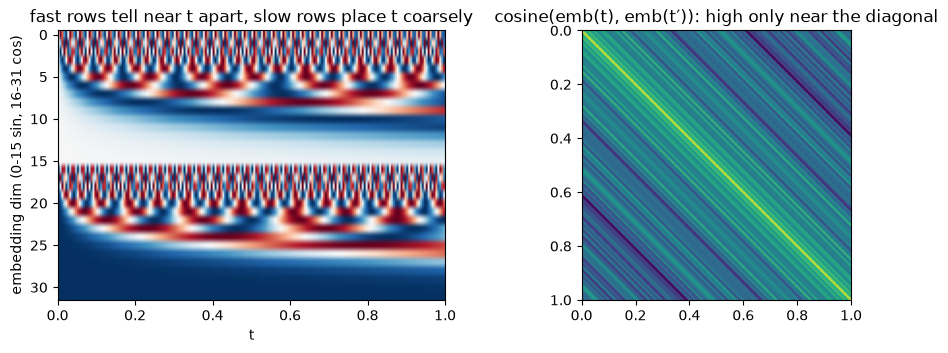

e.shape = torch.Size([200, 32])


In [26]:
@lambda f: f()
def probe():
    t = torch.linspace(0, 1, 200)
    e = time_embedding(t)  # [200, 32]
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.5))
    a.imshow(e.T, aspect='auto', cmap='RdBu', extent=[0, 1, 31.5, -0.5])
    a.set_xlabel('t')
    a.set_ylabel('embedding dim (0-15 sin, 16-31 cos)')
    a.set_title('fast rows tell near t apart, slow rows place t coarsely')
    sim = F.cosine_similarity(e[:, None], e[None], dim=-1)  # [200, 200]
    b.imshow(sim, cmap='viridis', extent=[0, 1, 1, 0])
    b.set_title('cosine(emb(t), emb(t′)): high only near the diagonal')
    plt.show()
    show(e.shape)

Does it help a net read `t`? A toy target that changes sharply with `t`: `y = t + sin(25t)` for `t > 0.5`, `y = t` below. The same 2-layer MLP (128 wide, Mish) fed raw `t`, or the embedding at scale 1000, or at scale 1. 1000 Adam steps on 2048 random `t`, test on a fine grid.


In [27]:
@lambda f: f()
def probe():
    def target(t: Tensor) -> Tensor:
        return t + torch.sin(25 * t) * (t > 0.5).float()

    t_train, t_test = torch.rand(2048), torch.linspace(0, 1, 500)
    inputs = {
        'raw t': (1, lambda t: t[:, None]),
        'emb, ×1000': (32, lambda t: time_embedding(t)),
        'emb, ×1': (32, lambda t: time_embedding(t, scale=1.0)),
    }
    for name, (dim, feat) in inputs.items():
        torch.manual_seed(0)
        net = nn.Sequential(
            nn.Linear(dim, 128), nn.Mish(), nn.Linear(128, 128), nn.Mish(), nn.Linear(128, 1)
        )
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        for _ in range(1001):
            loss = ((net(feat(t_train))[:, 0] - target(t_train)) ** 2).mean()
            opt.zero_grad()
            loss.backward()
            opt.step()
        with torch.no_grad():
            test = ((net(feat(t_test))[:, 0] - target(t_test)) ** 2).mean()
        print(f'{name:11s} train {loss.item():.4f}   test {test.item():.4f}')

raw t       train 0.0255   test 0.0258
emb, ×1000  train 0.0000   test 0.0000
emb, ×1     train 0.1985   test 0.1979


### step 5 — the U: down 16 → 8 → 4, back up, with skip connections

Steps 1-4 assembled. Every block is a `FiLMResBlock` reading the same condition (scene features + embedded `t`). Going down, a stride-2 conv halves the length and the channels grow; at the bottom each of the 4 positions sees the whole chunk. Coming up, a transposed conv doubles the length and the saved activation from the same level is **concatenated** on (the U's skip connections), so fine timing lost on the way down comes straight back:

```
x  [8, 16] ── R(8→64) R(64→64) ──────────── s1 [64, 16] ─────────────────┐
                    │ down: Conv1d stride 2                               │ cat
                [64, 8] ── R(64→128) R(128→128) ── s2 [128, 8] ──┐       │
                                  │ down                           │ cat  │
                              [128, 4] ── R(128→256) R(256→256)    │      │
                                  │ up: ConvTranspose1d ×2         │      │
                              [256, 8] ++ s2 = [384, 8] ── R(384→128) R(128→128)
                                                    │ up                  │
                                                [128, 16] ++ s1 = [192, 16] ── R(192→64) R(64→64)
                                                                                │
                                                       Conv1dBlock(64→64), Conv1d(64→8, 1×1) -> v [8, 16]
```

Length out of a stride-2 conv (kernel 3, padding 1): `(L + 2 − 3) // 2 + 1 = L/2` for even L. Transposed conv (kernel 4, stride 2, padding 1): `(L − 1)·2 − 2 + 4 = 2L`.


In [28]:
class UNet1D(nn.Module):
    # (noisy chunk as channels × time, condition) -> velocity, same layout
    def __init__(
        self, cond_dim: int, c_act: int = 8, widths: tuple[int, int, int] = (64, 128, 256)
    ):
        super().__init__()
        w1, w2, w3 = widths
        R = lambda a, b: FiLMResBlock(a, b, cond_dim)  # noqa: E731
        self.enc1 = nn.ModuleList([R(c_act, w1), R(w1, w1)])
        self.down1 = nn.Conv1d(w1, w1, 3, stride=2, padding=1)  # 16 -> 8
        self.enc2 = nn.ModuleList([R(w1, w2), R(w2, w2)])
        self.down2 = nn.Conv1d(w2, w2, 3, stride=2, padding=1)  # 8 -> 4
        self.mid = nn.ModuleList([R(w2, w3), R(w3, w3)])
        self.up2 = nn.ConvTranspose1d(w3, w3, 4, stride=2, padding=1)  # 4 -> 8
        self.dec2 = nn.ModuleList([R(w3 + w2, w2), R(w2, w2)])  # + s2's channels
        self.up1 = nn.ConvTranspose1d(w2, w2, 4, stride=2, padding=1)  # 8 -> 16
        self.dec1 = nn.ModuleList([R(w2 + w1, w1), R(w1, w1)])  # + s1's channels
        self.out = nn.Sequential(Conv1dBlock(w1, w1), nn.Conv1d(w1, c_act, 1))

    def forward(self, x: Tensor, cond: Tensor) -> Tensor:
        # x: [B, 8, L], L divisible by 4
        # cond: [B, cond_dim]
        # out: [B, 8, L]
        def run(blocks: nn.ModuleList, h: Tensor) -> Tensor:
            for blk in blocks:
                h = blk(h, cond)
            return h

        s1 = run(self.enc1, x)  # [B, 64, L]
        s2 = run(self.enc2, self.down1(s1))  # [B, 128, L/2]
        h = run(self.mid, self.down2(s2))  # [B, 256, L/4]
        h = run(self.dec2, torch.cat([self.up2(h), s2], dim=1))  # [B, 384, L/2] -> [B, 128, L/2]
        h = run(self.dec1, torch.cat([self.up1(h), s1], dim=1))  # [B, 192, L] -> [B, 64, L]
        return self.out(h)  # [B, 8, L]

In [29]:
@lambda f: f()
def probe():
    unet = UNet1D(cond_dim=32).to(dev)
    shapes = []
    for name, m in unet.named_children():  # each part's output shape, recorded as it runs
        m.register_forward_hook(lambda m, i, o, name=name: shapes.append((name, tuple(o.shape))))
    v = unet(x1.transpose(1, 2), torch.randn(4, 32, device=dev))
    for name, s in shapes:
        print(f'{name:6s} -> {s}')
    show(v.shape)

down1  -> (4, 64, 8)
down2  -> (4, 128, 4)
up2    -> (4, 256, 8)
up1    -> (4, 128, 16)
out    -> (4, 8, 16)
v.shape = torch.Size([4, 8, 16])


The velocity net around it: step 11's interface (`top, wrist, state, xt, t` → `[B, K, 8]`), so the training loop, sampler and tests from the MLP notebook drop in unchanged. The condition is the scene (the MLP's two encoders + state, 264 numbers) plus `t` embedded (step 4) and passed through a small MLP, as Diffusion Policy does.


In [30]:
class UNetVelocityNet(nn.Module):
    def __init__(self, t_dim: int = 64):
        super().__init__()
        self.top = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.wrist = nn.Sequential(make_conv(), SpatialSoftmax(16, 16))
        self.t_dim = t_dim
        self.t_mlp = nn.Sequential(
            nn.Linear(t_dim, 4 * t_dim), nn.Mish(), nn.Linear(4 * t_dim, t_dim)
        )
        self.unet = UNet1D(cond_dim=128 * 2 + 8 + t_dim)  # top, wrist, state, t

    def forward(self, top: Tensor, wrist: Tensor, state: Tensor, xt: Tensor, t: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # state: [B, 8] radians
        # xt: [B, K, 8] the noisy chunk at time t, std units of action
        # t: [B] in [0, 1]
        # out: [B, K, 8] the predicted velocity, std units per unit t
        f_top = self.top((top - stats.top.mean) / stats.top.std)  # [B, 128]
        f_wrist = self.wrist((wrist - stats.wrist.mean) / stats.wrist.std)  # [B, 128]
        st = (state - stats.state.mean) / stats.state.std  # [B, 8]
        f_t = self.t_mlp(time_embedding(t, self.t_dim))  # [B, 64]
        cond = torch.cat([f_top, f_wrist, st, f_t], dim=-1)  # [B, 328]
        return self.unet(xt.transpose(1, 2), cond).transpose(1, 2)  # [B, 8, K] -> [B, K, 8]

In [31]:
@lambda f: f()
def probe():
    net = UNetVelocityNet().to(dev)
    i = torch.arange(4, device=dev)
    v = net(
        data.top.train[i].float() / 255,
        data.wrist.train[i].float() / 255,
        data.state.train[i],
        torch.randn(4, K, 8, device=dev),
        torch.rand(4, device=dev),
    )
    count = lambda m: sum(p.numel() for p in m.parameters())  # noqa: E731
    show(v.shape, count(net), count(net.unet), count(net.top) + count(net.wrist), count(net.t_mlp))
    show('MLP velocity net (flow_matching_namespace): 867,202 params')

v.shape = torch.Size([4, 16, 8])
count(net) = 3846602
count(net.unet) = 3476360
count(net.top) + count(net.wrist) = 337154
count(net.t_mlp) = 33088
MLP velocity net (flow_matching_namespace): 867,202 params


### step 6 — train it (copied from `flow_matching_namespace.ipynb` step 12, net swapped; ~5 min the first time, cached after)

The same batches, loss, Euler sampler, val error, and cached `train` / `load`; only `VelocityNet` → `UNetVelocityNet`. Same seed, steps, lr, batch 64, so the logs compare line by line with the MLP's (10k: val arm 0.0174, gripper 0.0909).


In [32]:
from typing import Literal, Protocol

import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # as bc_2 step 30
    # x: [B, 3, H, W]
    # out: [B, 3, H, W], the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode='replicate')  # [B, 3, H + 2p, W + 2p]
    dy, dx = (int(d) for d in torch.randint(0, 2 * pad + 1, (2,)))
    return x[:, :, dy : dy + H, dx : dx + W]


class Batch(Protocol):  # what get_batch returns: a namespace with these fields
    top: Tensor  # [B, 3, 128, 128] floats in [0, 1]
    wrist: Tensor  # [B, 3, 128, 128] floats in [0, 1]
    state: Tensor  # [B, 8] radians
    chunks: Tensor  # [B, K, 8] radians
    pad: Tensor  # [B, K] bool, True past the demo's end


def get_batch(part: Literal['train', 'val'], i: Tensor) -> Batch:
    # rows i of one part, every field at once; images to floats in [0, 1] only now
    def take(x) -> Tensor:  # x: a train/val pair from step 9's split
        return (x.train if part == 'train' else x.val)[i]

    return namespace(
        top=take(data.top).float() / 255,  # [B, 3, 128, 128]
        wrist=take(data.wrist).float() / 255,  # [B, 3, 128, 128]
        state=take(data.state),  # [B, 8]
        chunks=take(data.chunks),  # [B, K, 8] radians
        pad=take(data.pad),  # [B, K] bool
    )

In [33]:
def flow_loss(net: UNetVelocityNet, b: Batch, shift: int = 4) -> Tensor:
    # out: [], the toy's loss on chunks: MSE between predicted and true speed, padded steps skipped
    x1 = (b.chunks - stats.action.mean) / stats.action.std  # [B, K, 8], the demo chunk, std units
    x0 = torch.randn_like(x1)  # [B, K, 8], noise
    t = torch.rand(len(x1), device=dev)  # [B]
    xt = (1 - t[:, None, None]) * x0 + t[:, None, None] * x1  # [B, K, 8], the point at time t
    v = net(random_shift(b.top, shift), random_shift(b.wrist, shift), b.state, xt, t)
    err = (v - (x1 - x0)) ** 2  # [B, K, 8], MSE on purpose: its best guess is the mean speed
    keep = (~b.pad)[..., None].float()  # [B, K, 1], 0 on padded steps
    return (err * keep).sum() / (keep.sum() * 8)  # over real values only

In [34]:
torch.manual_seed(0)
b = get_batch('train', torch.randint(0, len(data.state.train), (64,), device=dev))
with torch.no_grad():
    loss = flow_loss(
        UNetVelocityNet().to(dev), b
    )  # untrained: v ~ 0, so about E|x1 - x0|² = 1 + 1 = 2
show(b.pad.float().mean(), loss)

b.pad.float().mean() = tensor(0.0342, device='cuda:0')
loss = tensor(2.2450, device='cuda:0')


In [35]:
@torch.no_grad()
def sample(
    net: UNetVelocityNet, top: Tensor, wrist: Tensor, state: Tensor, steps: int = 10
) -> Tensor:
    # the toy's sampler (flow_matching.ipynb step 4), per observation
    # out: [B, K, 8] radians, one sampled plan per observation
    x = torch.randn(len(state), K, 8, device=dev)  # [B, K, 8], fresh noise
    for k in range(steps):
        t = torch.full((len(state),), k / steps, device=dev)  # [B]
        x = x + net(top, wrist, state, x, t) / steps  # Euler: x += speed * dt
    return x * stats.action.std + stats.action.mean  # std units -> radians


@torch.no_grad()
def val_error(net: UNetVelocityNet) -> Tensor:
    # out: [8], mean |error| of one sampled plan's FIRST action per val frame, radians,
    # comparable with BC and ACT. 256 frames at a time, never shifted
    n = len(data.state.val)
    firsts = []
    for j in range(0, n, 256):
        b = get_batch('val', torch.arange(j, min(j + 256, n), device=dev))
        firsts.append(sample(net, b.top, b.wrist, b.state)[:, 0])  # [<=256, 8]
    return (torch.cat(firsts) - data.chunks.val[:, 0]).abs().mean(0)

In [36]:
@lambda f: f()
def probe():
    # seconds per training step, to size the train cell (50 steps after 5 warm-up)
    import time

    net = UNetVelocityNet().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3)
    for step in range(55):
        if step == 5:
            torch.cuda.synchronize()
            start = time.time()
        b = get_batch('train', torch.randint(0, len(data.state.train), (64,), device=dev))
        loss = flow_loss(net, b)
        opt.zero_grad()
        loss.backward()
        opt.step()
    torch.cuda.synchronize()
    per_step = (time.time() - start) / 50
    show(per_step, f'10k steps ≈ {per_step * 10000 / 60:.1f} min of training')

per_step = 0.026580586433410644
10k steps ≈ 4.4 min of training


In [37]:
@cache
def train(seed: int = 0, steps: int = 10000, lr: float = 1e-3) -> namespace:
    torch.manual_seed(seed)
    net = UNetVelocityNet().to(dev)
    opt = torch.optim.AdamW(net.parameters(), lr=lr)
    err = torch.zeros(8)
    for step in range(steps + 1):
        b = get_batch('train', torch.randint(0, len(data.state.train), (64,), device=dev))
        loss = flow_loss(net, b)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 2000 == 0:
            net.eval()
            err = val_error(net).cpu()
            net.train()
            print(
                f'{step:5d}  loss {loss.item():.3f}  val arm {err[:7].mean():.4f}  gripper {err[7]:.4f}'
            )
    # weights on the CPU, so the cache holds no GPU tensors
    return namespace(weights={k: v.cpu() for k, v in net.state_dict().items()}, err=err)

train: cached, 1 call(s) stored


In [38]:
def load(train_steps: int = 10000, log: bool = False) -> UNetVelocityNet:
    # the net train(steps=train_steps) made, from its cache; log: replay its training log
    net = UNetVelocityNet().to(dev)
    net.load_state_dict((train if log else train.quiet)(steps=train_steps).weights)
    return net.eval()


vnet = load(log=True)

    0  loss 2.245  val arm 0.1642  gripper 0.4861
 2000  loss 0.112  val arm 0.0170  gripper 0.0670
 4000  loss 0.103  val arm 0.0134  gripper 0.0466
 6000  loss 0.091  val arm 0.0126  gripper 0.0402
 8000  loss 0.073  val arm 0.0115  gripper 0.0381
10000  loss 0.061  val arm 0.0117  gripper 0.0351


**Result (step 6):** at 10k steps the U-Net's val error is already below the MLP's: arm 0.0117 vs 0.0174, gripper 0.0351 vs 0.0909 (the MLP needed 30k for arm 0.0118, gripper 0.0618). Loss 0.061 vs 0.188.

### step 7 — the sim, the rollout and both tests (copied from `flow_matching_namespace.ipynb` steps 13-15)

`same_start`: one scene 20 times, only the noise differs: does it use both bins? `spread`: 20 scenes, once each: does it work? Each at 8 and 16 of 16 steps played per plan. MLP at 10k: same start 5/20 (8) and 17/20 (16, 9 right / 8 left); spread 7/20 and 15/20; the failures were slipped grasps left at the centre (`'between'`).


In [39]:
import logging
import os

# render without a window; must be set before mujoco loads
os.environ.setdefault('MUJOCO_GL', 'egl')

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite

logging.disable(logging.NOTSET)
logging.getLogger('robosuite_logs').setLevel(logging.ERROR)
from dream_robot.core.registry import make_env
from dream_robot.core.schema import Observation
from dream_robot.sims.robosuite.tasks.pick_place_two_bins.env import PickPlaceTwoBins

env: PickPlaceTwoBins = make_env(
    'robosuite/pick_place_two_bins_fixed'
)  # cube always at the centre, either bin wins

In [40]:
def frame(im: np.ndarray) -> Tensor:
    # im: [H, W, 3] uint8 from the sim
    # out: [1, 3, H, W] floats in [0, 1] on the GPU
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(dev).float() / 255


def predict(net: UNetVelocityNet, obs: Observation) -> NDArray[np.float32]:
    # out: [K, 8], one sampled plan from this observation; fresh noise each call
    st = torch.from_numpy(obs.state)[None].to(dev)  # [1, 8]
    plan = sample(net, frame(obs.images['top']), frame(obs.images['wrist']), st)[0].cpu().numpy()
    plan[:, 7] = np.clip(plan[:, 7], 0.0, 1.0)  # gripper commands must stay in [0, 1]
    return plan

In [41]:
from typing import NamedTuple

from dream_robot.core.video import observation_panel


class Outcome(NamedTuple):  # how one rollout ended
    success: bool
    where: str  # where the cube ended: 'left' / 'right' / 'between' / 'other'


def rollout(
    net: UNetVelocityNet, seed: int, n_exec: int = 8, frames: list | None = None
) -> Outcome:
    # sample a plan, play its first n_exec actions without looking, then sample again;
    # frames: if a list, one video frame per step is appended to it (wide view + both cameras)
    obs = env.reset(seed=seed)
    plan = []  # actions still to play from the last plan
    success = False
    for _ in range(600):
        if frames is not None:
            frames.append(observation_panel(env.render(), obs.images))
        if not plan:
            plan = list(predict(net, obs)[:n_exec])  # n_exec x [8]
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            success = r.success
            break
    cube = env.cube_pos
    b = env.which_bin(cube)  # index into env.bin_names, or None
    where = (
        env.bin_names[b] if b is not None else ('between' if env.between_bins(cube) else 'other')
    )
    return Outcome(success, where)

In [42]:
torch.manual_seed(0)
ok, where = rollout(vnet, 1000)
show(ok, where)

ok = True
where = 'left'


In [43]:
from collections import Counter


def score(results: list[Outcome]) -> str:
    # 'wins/n   {where: count}'
    wins = sum(r.success for r in results)
    return f'{wins:2d}/{len(results)}   {dict(Counter(r.where for r in results))}'

In [44]:
@cache
def same_start(train_steps: int = 10000, n_exec: int = 8) -> list[Outcome]:
    # does it use BOTH bins? One scene (env seed 1000) played 20 times; only the net's noise
    # differs (torch seed k). The expert flips a coin here, so the target is ~10 left, ~10 right.
    # BC and ACT are deterministic: the same bin 20/20 by construction
    net = load(train_steps)
    results = []
    for k in range(20):
        torch.manual_seed(k)
        results.append(rollout(net, 1000, n_exec))
    print(f'same start, {train_steps} steps, n_exec {n_exec}: {score(results)}')
    return results

same_start: cached, 1 call(s) stored


In [45]:
@cache
def spread(train_steps: int = 10000, n_exec: int = 8) -> list[Outcome]:
    # does it WORK? The standard eval, as for BC and ACT: 20 different scenes (env seeds
    # 1000-1019), one rollout each, one torch seed for the whole run. The cube is always at the
    # centre in T2-fixed, so the scenes differ only in the start's small jitter
    net = load(train_steps)
    torch.manual_seed(0)
    results = [rollout(net, seed, n_exec) for seed in range(1000, 1020)]
    print(f'spread,     {train_steps} steps, n_exec {n_exec}: {score(results)}')
    return results

spread: cached, 1 call(s) stored


In [46]:
# both tests at both ways of playing the plans (~10 min the first time, cached after)
for n_exec in [8, 16]:
    same_start(10000, n_exec)
    spread(10000, n_exec)

same start, 10000 steps, n_exec 8: 20/20   {'left': 14, 'right': 6}
spread,     10000 steps, n_exec 8: 19/20   {'left': 14, 'between': 1, 'right': 5}
same start, 10000 steps, n_exec 16: 20/20   {'left': 20}
spread,     10000 steps, n_exec 16: 18/20   {'left': 15, 'between': 2, 'right': 3}


**Result (step 7)**, 10k steps, U-Net vs MLP (`flow_matching_namespace.ipynb`), one seed each:

| plays per plan | net | same start: wins, where | spread: wins |
|---|---|---|---|
| 8 of 16 | MLP | 5/20: between 15, right 3, left 2 | 7/20 |
| 8 of 16 | **U-Net** | **20/20: left 14, right 6** | **19/20** |
| 16 of 16 | MLP | 17/20: right 9, left 8, between 3 | 15/20 |
| 16 of 16 | **U-Net** | **20/20: left 20** | 18/20 |

- **The grasp is solved at 10k**, even re-planning every 8 steps: the MLP's slipped grasps (`'between'`) are gone, as the lower val error suggested (gripper 0.035 vs 0.091). The MLP needed 30k for this.
- **The coin is not.** At 16 every run from one scene went left; at 8, 14 left / 6 right. With a 0.3 chance of right, 0/20 happens about 0.1% of the time, so at 16 the first plan almost always picks left, and the rights at 8 come from re-planning mid-way. A guess, not checked.
- So far both nets lean left once they grasp well (MLP at 30k: 17/3). One seed: seed 1 for both is what tells net from luck.

## wrap-up

**What the U-Net buys:** structure the MLP had to learn. Conv along the chunk's time axis (neighbouring steps move together, step 1), residual blocks (the input survives, each block learns a change, step 2), the condition in every block through FiLM (step 3), `t` as sines and cosines a layer can read (step 4: raw `t` 0.026 vs 0.0000 on a sharp toy), coarse-to-fine with skips (step 5). At 10k steps: val gripper 0.035 vs the MLP's 0.091, and 20/20 from one scene even re-planning every 8 steps, where the MLP slipped the grasp 15 times.

**Where it fails:** the coin. 20/20 left at 16 steps per plan, 14/6 at 8; the MLP at 30k leans the same way (17/3). One seed each, so unknown yet whether that is flow matching, these 100 demos, or luck. 4.4× the MLP's parameters (3.85M), so architecture and size are not separated.

**Toys that did not show what the textbook says:** a plain 20-block stack's gradient did not vanish (GroupNorm), and FiLM did not beat a concatenated condition on a sign-flip toy. Their real effect is only tested by the full net on the robot.

**Next:** the same velocity net as a small DiT (`flow_matching_dit.ipynb`): tokens per chunk step, self-attention, adaLN-zero.